# NLP Project Report
## TripAdvisor Hotel Reviews — Sentiment Analysis

**Course:** Natural Language Processing | E1CAA312  
**Class:** BCA IV SEM  
**Mentor:** Nagasri. P  
**Dataset:** TripAdvisor Hotel Reviews

In [1]:
# ============================================================
# CELL 1 : Install Libraries
# ============================================================

import sys
import subprocess

subprocess.check_call([sys.executable, "-m", "pip", "install",
                       "nltk", "scikit-learn", "pandas",
                       "matplotlib", "seaborn", "wordcloud"])

print("All libraries installed successfully!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.9/168.9 kB 1.7 MB/s eta 0:00:001.6 MB/s eta 0:00:01m
All libraries installed successfully!


In [5]:
# ============================================================
# CELL 2 : Import Libraries
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
import warnings
warnings.filterwarnings('ignore')

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             confusion_matrix, classification_report)
from wordcloud import WordCloud

nltk.download('punkt',     quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet',   quiet=True)
nltk.download('omw-1.4',   quiet=True)

print("All imports done!")

All imports done!


In [7]:
# ============================================================
# CELL 3 : Load Dataset
# ============================================================

df = pd.read_csv("/Users/dakshrajsinghkurki/Downloads/tripadvisor_hotel_reviews.csv")

print("Dataset loaded successfully!")
print("Shape   :", df.shape)
print("Columns :", list(df.columns))
df.head()

Dataset loaded successfully!
Shape   : (20491, 2)
Columns : ['Review', 'Rating']


,Review,Rating
0,nice hotel expensive parking got good deal sta...,4
1,ok nothing special charge diamond member hilto...,2
2,nice rooms not 4* experience hotel monaco seat...,3
3,"unique, great stay, wonderful time hotel monac...",5
4,"great stay great stay, went seahawk game aweso...",5


In [9]:
# ============================================================
# CELL 4 : Basic Info and Missing Values
# ============================================================

print("Dataset Info:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nRating Distribution:")
print(df['Rating'].value_counts().sort_index())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20491 entries, 0 to 20490
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Review  20491 non-null  object
 1   Rating  20491 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 320.3+ KB
None

Missing Values:
Review    0
Rating    0
dtype: int64

Rating Distribution:
Rating
1    1421
2    1793
3    2184
4    6039
5    9054
Name: count, dtype: int64


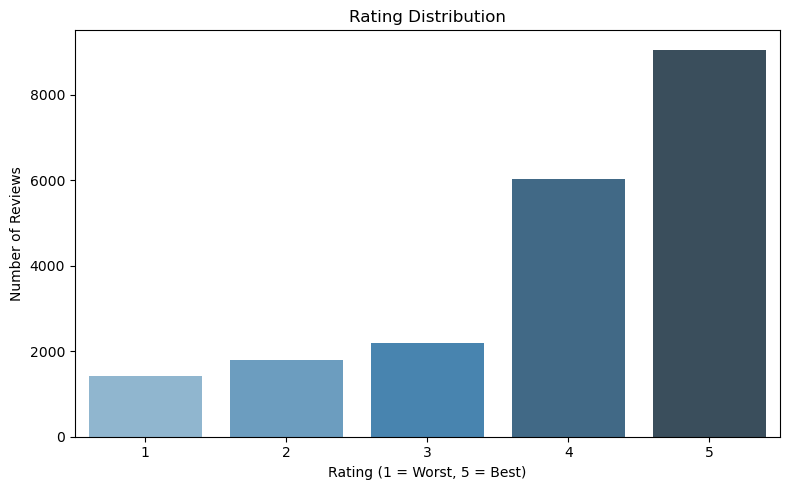

In [11]:
# ============================================================
# CELL 5 : Plot Rating Distribution
# ============================================================

plt.figure(figsize=(8, 5))
sns.countplot(x='Rating', data=df, palette='Blues_d')
plt.title('Rating Distribution')
plt.xlabel('Rating (1 = Worst, 5 = Best)')
plt.ylabel('Number of Reviews')
plt.tight_layout()
plt.show()

Sentiment counts:
Sentiment
Positive    15093
Negative     3214
Neutral      2184
Name: count, dtype: int64


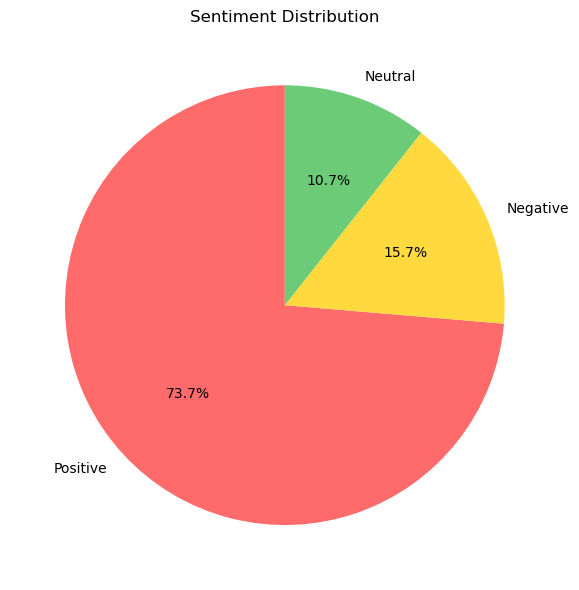

In [13]:
# ============================================================
# CELL 6 : Create Sentiment Labels
#   Rating 1-2  -->  Negative
#   Rating 3    -->  Neutral
#   Rating 4-5  -->  Positive
# ============================================================

def get_sentiment(rating):
    if rating <= 2:
        return 'Negative'
    elif rating == 3:
        return 'Neutral'
    else:
        return 'Positive'

df['Sentiment'] = df['Rating'].apply(get_sentiment)

print("Sentiment counts:")
print(df['Sentiment'].value_counts())

plt.figure(figsize=(6, 6))
df['Sentiment'].value_counts().plot.pie(
    autopct='%1.1f%%',
    colors=['#ff6b6b', '#ffd93d', '#6bcb77'],
    startangle=90
)
plt.title('Sentiment Distribution')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# CELL 7 : Text Preprocessing Functions (10 Steps)
# ============================================================

stemmer    = PorterStemmer()
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# Step 1 : Convert to Lowercase
def to_lowercase(text):
    return text.lower()

# Step 2 : Remove Punctuation
def remove_punctuation(text):
    return text.translate(str.maketrans('', '', string.punctuation))

# Step 3 : Remove Special Characters
def remove_special_chars(text):
    return re.sub(r'[^a-zA-Z0-9\s]', '', text)

# Step 4 : Remove Numbers
def remove_numbers(text):
    return re.sub(r'\d+', '', text)

# Step 5 : Remove Extra Spaces
def remove_extra_spaces(text):
    return re.sub(r'\s+', ' ', text).strip()

# Step 6 : Tokenization
def tokenize(text):
    return word_tokenize(text)

# Step 7 : Remove Stopwords
def remove_stopwords(tokens):
    return [w for w in tokens if w not in stop_words]

# Step 8 : Stemming
def apply_stemming(tokens):
    return [stemmer.stem(w) for w in tokens]

# Step 9 : Lemmatization
def apply_lemmatization(tokens):
    return [lemmatizer.lemmatize(w) for w in tokens]

# Step 10 : Normalize - Remove very short words
def normalize(tokens):
    return [w for w in tokens if len(w) > 2]

print("All 10 preprocessing functions ready!")

All 10 preprocessing functions ready!


In [17]:
# ============================================================
# CELL 8 : Apply Full Preprocessing Pipeline
# ============================================================

def preprocess(text):
    text   = to_lowercase(text)
    text   = remove_punctuation(text)
    text   = remove_special_chars(text)
    text   = remove_numbers(text)
    text   = remove_extra_spaces(text)
    tokens = tokenize(text)
    tokens = remove_stopwords(tokens)
    tokens = apply_stemming(tokens)
    tokens = apply_lemmatization(tokens)
    tokens = normalize(tokens)
    return ' '.join(tokens)

# Show before and after for 3 reviews
print("Before and After Preprocessing:\n")
for i in range(3):
    print("Review", i + 1)
    print("  BEFORE :", df['Review'].iloc[i][:100])
    print("  AFTER  :", preprocess(df['Review'].iloc[i])[:100])
    print()

# Apply to full dataset
print("Preprocessing all reviews... (please wait about 1 minute)")
df['Cleaned_Review'] = df['Review'].apply(preprocess)
print("Preprocessing done!")

Before and After Preprocessing:

Review 1
  BEFORE : nice hotel expensive parking got good deal stay hotel anniversary, arrived late evening took advice 
  AFTER  : nice hotel expens park got good deal stay hotel anniversari arriv late even took advic previou revie

Review 2
  BEFORE : ok nothing special charge diamond member hilton decided chain shot 20th anniversary seattle, start b
  AFTER  : noth special charg diamond member hilton decid chain shot anniversari seattl start book suit paid ex

Review 3
  BEFORE : nice rooms not 4* experience hotel monaco seattle good hotel n't 4* level.positives large bathroom m
  AFTER  : nice room experi hotel monaco seattl good hotel levelposit larg bathroom mediterranean suit comfort 

Preprocessing all reviews... (please wait about 1 minute)
Preprocessing done!


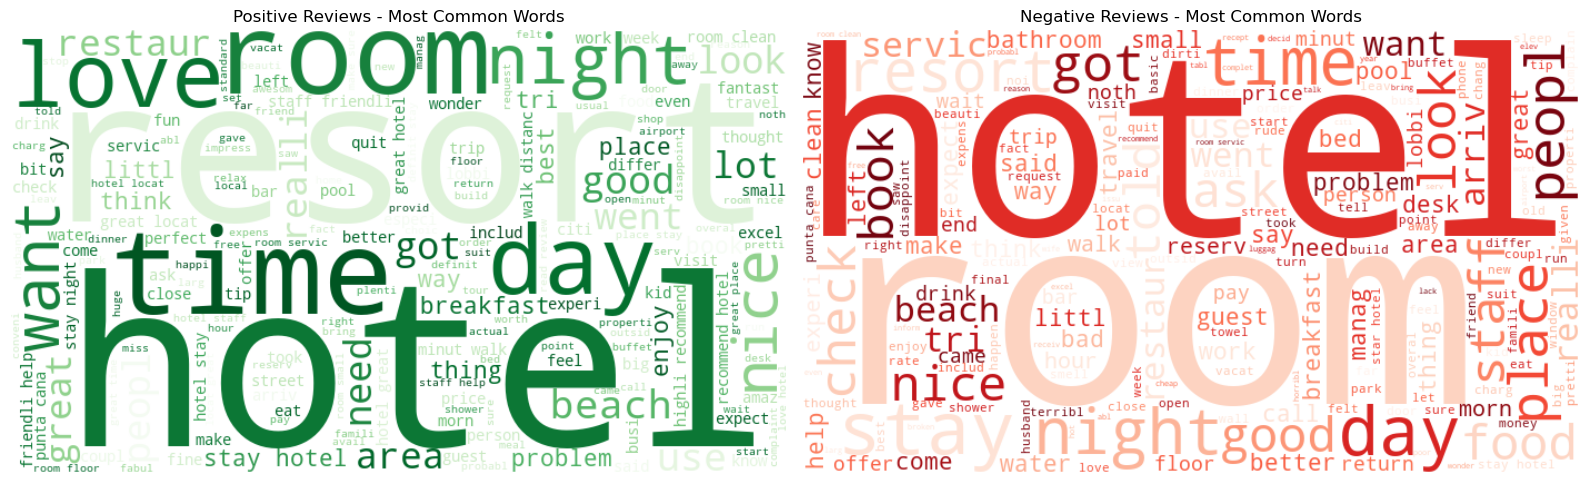

In [20]:
# ============================================================
# CELL 9 : WordCloud
# ============================================================

positive_text = ' '.join(df[df['Sentiment'] == 'Positive']['Cleaned_Review'])
negative_text = ' '.join(df[df['Sentiment'] == 'Negative']['Cleaned_Review'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

wc1 = WordCloud(width=700, height=400,
                background_color='white',
                colormap='Greens').generate(positive_text)
axes[0].imshow(wc1, interpolation='bilinear')
axes[0].set_title('Positive Reviews - Most Common Words')
axes[0].axis('off')

wc2 = WordCloud(width=700, height=400,
                background_color='white',
                colormap='Reds').generate(negative_text)
axes[1].imshow(wc2, interpolation='bilinear')
axes[1].set_title('Negative Reviews - Most Common Words')
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# CELL 10 : Train / Test Split
# ============================================================

X = df['Cleaned_Review']
y = df['Sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples :", len(X_train))
print("Testing  samples :", len(X_test))

Training samples : 16392
Testing  samples : 4099


Bag of Words:
  Train shape : (16392, 5000)
  Test  shape : (4099, 5000)


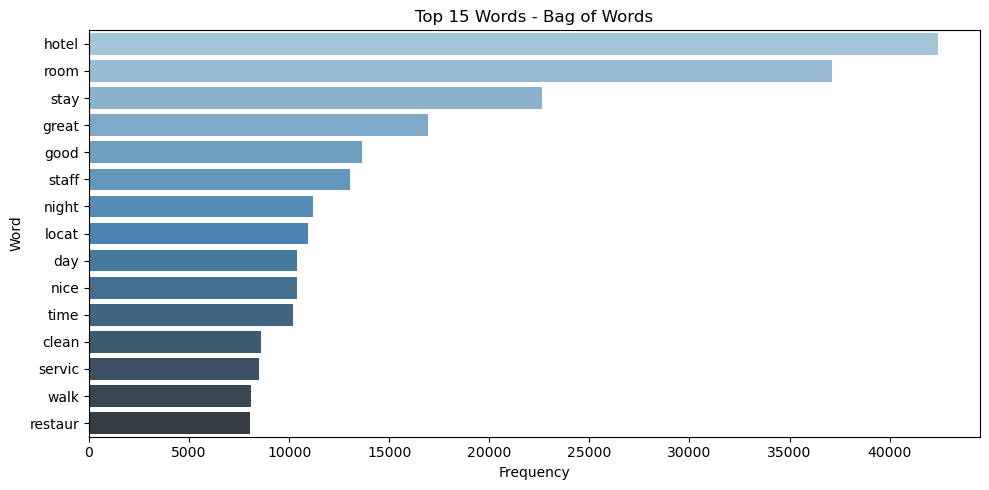

In [22]:
# ============================================================
# CELL 11 : Feature Extraction - Bag of Words
# ============================================================

bow = CountVectorizer(max_features=5000)
X_train_bow = bow.fit_transform(X_train)
X_test_bow  = bow.transform(X_test)

print("Bag of Words:")
print("  Train shape :", X_train_bow.shape)
print("  Test  shape :", X_test_bow.shape)

bow_freq = pd.DataFrame({
    'Word'      : bow.get_feature_names_out(),
    'Frequency' : X_train_bow.toarray().sum(axis=0)
}).sort_values('Frequency', ascending=False).head(15)

plt.figure(figsize=(10, 5))
sns.barplot(x='Frequency', y='Word', data=bow_freq, palette='Blues_d')
plt.title('Top 15 Words - Bag of Words')
plt.tight_layout()
plt.show()

TF-IDF:
  Train shape : (16392, 5000)
  Test  shape : (4099, 5000)


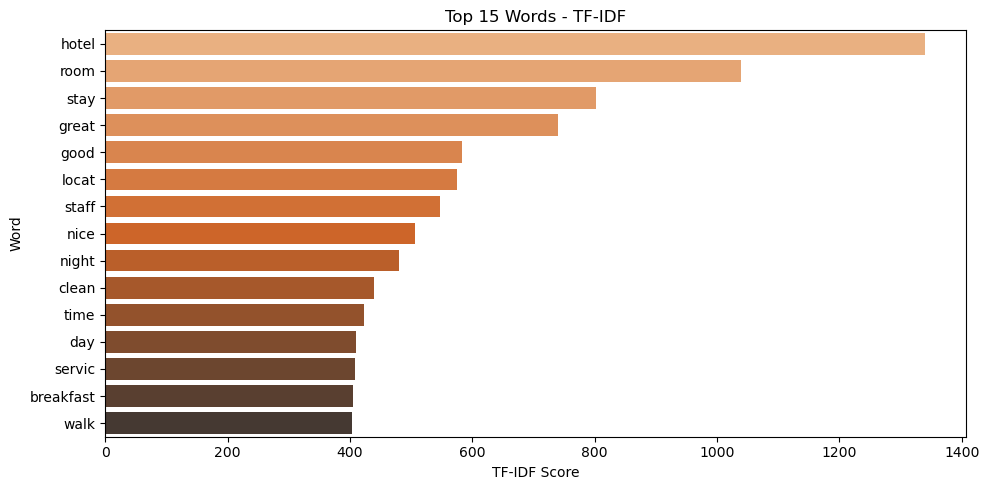

In [26]:
# ============================================================
# CELL 12 : Feature Extraction - TF-IDF
# ============================================================

tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print("TF-IDF:")
print("  Train shape :", X_train_tfidf.shape)
print("  Test  shape :", X_test_tfidf.shape)

tfidf_freq = pd.DataFrame({
    'Word'         : tfidf.get_feature_names_out(),
    'TF-IDF Score' : X_train_tfidf.toarray().sum(axis=0)
}).sort_values('TF-IDF Score', ascending=False).head(15)

plt.figure(figsize=(10, 5))
sns.barplot(x='TF-IDF Score', y='Word', data=tfidf_freq, palette='Oranges_d')
plt.title('Top 15 Words - TF-IDF')
plt.tight_layout()
plt.show()

In [28]:
# ============================================================
# CELL 13 : Model 1 - Naive Bayes + Bag of Words
# ============================================================

nb_bow = MultinomialNB()
nb_bow.fit(X_train_bow, y_train)
y_pred_nb_bow = nb_bow.predict(X_test_bow)

print("Naive Bayes + Bag of Words")
print("Accuracy  :", round(accuracy_score(y_test, y_pred_nb_bow), 4))
print("Precision :", round(precision_score(y_test, y_pred_nb_bow, average='weighted'), 4))
print("Recall    :", round(recall_score(y_test, y_pred_nb_bow, average='weighted'), 4))
print("F1 Score  :", round(f1_score(y_test, y_pred_nb_bow, average='weighted'), 4))
print()
print(classification_report(y_test, y_pred_nb_bow))

Naive Bayes + Bag of Words
Accuracy  : 0.8112
Precision : 0.8258
Recall    : 0.8112
F1 Score  : 0.8179

              precision    recall  f1-score   support

    Negative       0.73      0.76      0.75       643
     Neutral       0.31      0.38      0.34       437
    Positive       0.92      0.89      0.90      3019

    accuracy                           0.81      4099
   macro avg       0.65      0.67      0.66      4099
weighted avg       0.83      0.81      0.82      4099



In [30]:
# ============================================================
# CELL 14 : Model 2 - Naive Bayes + TF-IDF
# ============================================================

nb_tfidf = MultinomialNB()
nb_tfidf.fit(X_train_tfidf, y_train)
y_pred_nb_tfidf = nb_tfidf.predict(X_test_tfidf)

print("Naive Bayes + TF-IDF")
print("Accuracy  :", round(accuracy_score(y_test, y_pred_nb_tfidf), 4))
print("Precision :", round(precision_score(y_test, y_pred_nb_tfidf, average='weighted'), 4))
print("Recall    :", round(recall_score(y_test, y_pred_nb_tfidf, average='weighted'), 4))
print("F1 Score  :", round(f1_score(y_test, y_pred_nb_tfidf, average='weighted'), 4))
print()
print(classification_report(y_test, y_pred_nb_tfidf))

Naive Bayes + TF-IDF
Accuracy  : 0.8168
Precision : 0.7328
Recall    : 0.8168
F1 Score  : 0.7625

              precision    recall  f1-score   support

    Negative       0.86      0.54      0.66       643
     Neutral       0.00      0.00      0.00       437
    Positive       0.81      0.99      0.89      3019

    accuracy                           0.82      4099
   macro avg       0.56      0.51      0.52      4099
weighted avg       0.73      0.82      0.76      4099



In [32]:
# ============================================================
# CELL 15 : Model 3 - Logistic Regression + Bag of Words
# ============================================================

lr_bow = LogisticRegression(max_iter=1000, random_state=42)
lr_bow.fit(X_train_bow, y_train)
y_pred_lr_bow = lr_bow.predict(X_test_bow)

print("Logistic Regression + Bag of Words")
print("Accuracy  :", round(accuracy_score(y_test, y_pred_lr_bow), 4))
print("Precision :", round(precision_score(y_test, y_pred_lr_bow, average='weighted'), 4))
print("Recall    :", round(recall_score(y_test, y_pred_lr_bow, average='weighted'), 4))
print("F1 Score  :", round(f1_score(y_test, y_pred_lr_bow, average='weighted'), 4))
print()
print(classification_report(y_test, y_pred_lr_bow))

Logistic Regression + Bag of Words
Accuracy  : 0.8236
Precision : 0.8165
Recall    : 0.8236
F1 Score  : 0.8199

              precision    recall  f1-score   support

    Negative       0.73      0.74      0.74       643
     Neutral       0.32      0.28      0.30       437
    Positive       0.91      0.92      0.91      3019

    accuracy                           0.82      4099
   macro avg       0.65      0.65      0.65      4099
weighted avg       0.82      0.82      0.82      4099



In [34]:
# ============================================================
# CELL 16 : Model 4 - Logistic Regression + TF-IDF
# ============================================================

lr_tfidf = LogisticRegression(max_iter=1000, random_state=42)
lr_tfidf.fit(X_train_tfidf, y_train)
y_pred_lr_tfidf = lr_tfidf.predict(X_test_tfidf)

print("Logistic Regression + TF-IDF")
print("Accuracy  :", round(accuracy_score(y_test, y_pred_lr_tfidf), 4))
print("Precision :", round(precision_score(y_test, y_pred_lr_tfidf, average='weighted'), 4))
print("Recall    :", round(recall_score(y_test, y_pred_lr_tfidf, average='weighted'), 4))
print("F1 Score  :", round(f1_score(y_test, y_pred_lr_tfidf, average='weighted'), 4))
print()
print(classification_report(y_test, y_pred_lr_tfidf))

Logistic Regression + TF-IDF
Accuracy  : 0.8575
Precision : 0.8262
Recall    : 0.8575
F1 Score  : 0.8299

              precision    recall  f1-score   support

    Negative       0.79      0.80      0.79       643
     Neutral       0.48      0.13      0.21       437
    Positive       0.88      0.98      0.93      3019

    accuracy                           0.86      4099
   macro avg       0.72      0.63      0.64      4099
weighted avg       0.83      0.86      0.83      4099



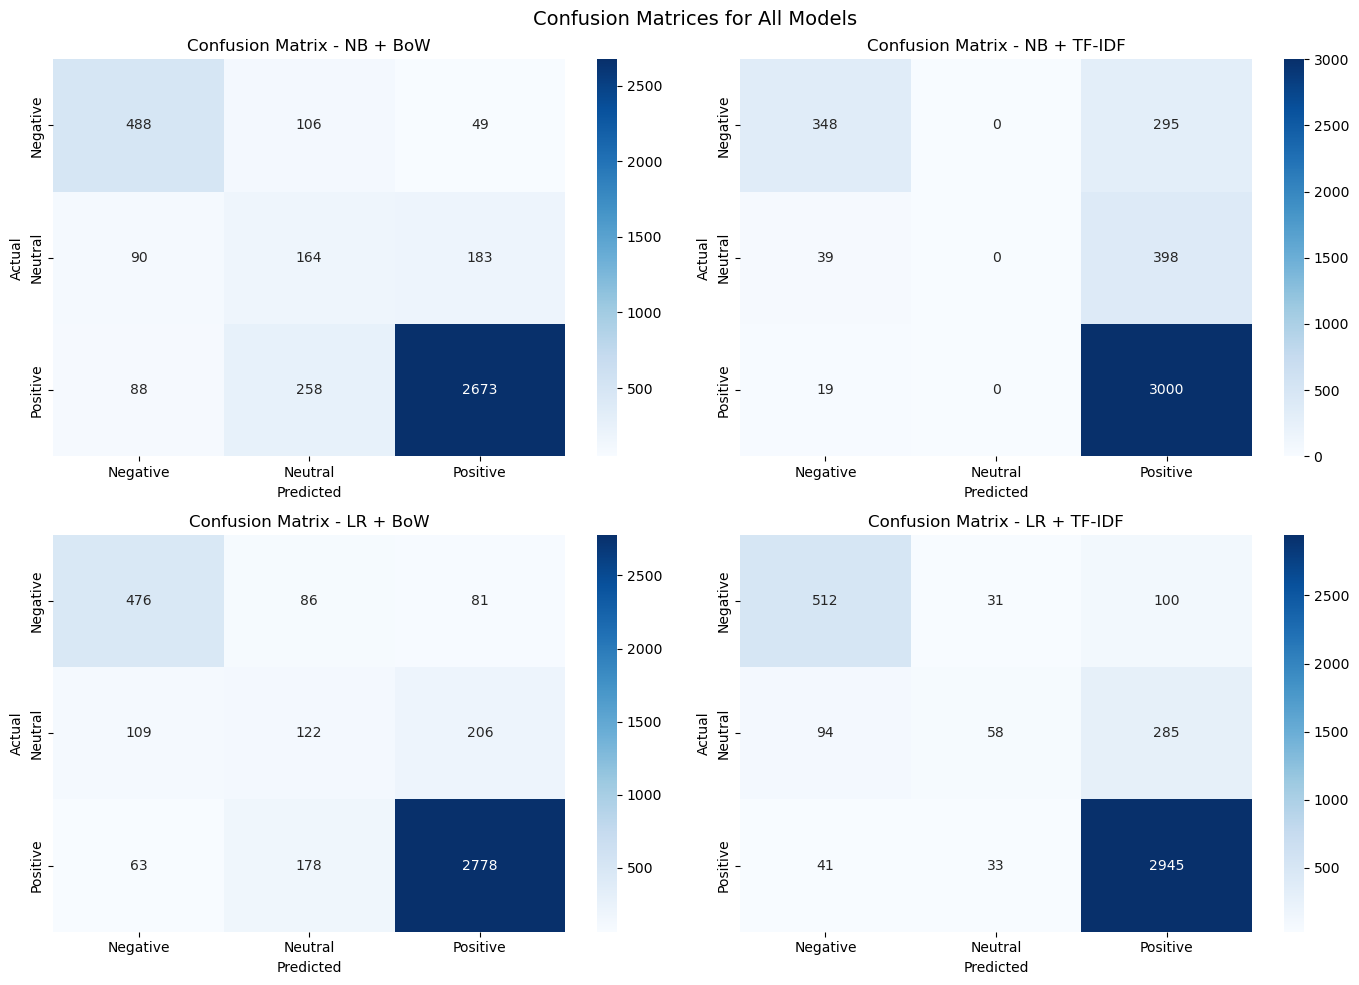

In [36]:
# ============================================================
# CELL 17 : Confusion Matrices - All 4 Models
# ============================================================

labels = ['Negative', 'Neutral', 'Positive']

all_models = [
    ("NB + BoW",    y_pred_nb_bow),
    ("NB + TF-IDF", y_pred_nb_tfidf),
    ("LR + BoW",    y_pred_lr_bow),
    ("LR + TF-IDF", y_pred_lr_tfidf),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(all_models):
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels, ax=axes[i])
    axes[i].set_title('Confusion Matrix - ' + name)
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.suptitle('Confusion Matrices for All Models', fontsize=14)
plt.tight_layout()
plt.show()

Model Accuracy Summary:
         Model  Accuracy
0  LR + TF-IDF  0.857526
1     LR + BoW  0.823616
2  NB + TF-IDF  0.816785
3     NB + BoW  0.811173


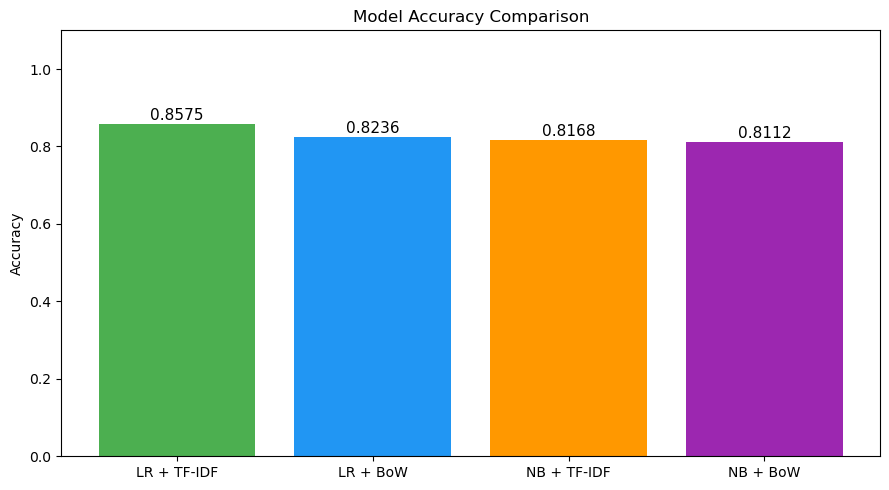

In [38]:
# ============================================================
# CELL 18 : Model Accuracy Comparison
# ============================================================

results = pd.DataFrame({
    'Model'    : ['NB + BoW', 'NB + TF-IDF', 'LR + BoW', 'LR + TF-IDF'],
    'Accuracy' : [
        accuracy_score(y_test, y_pred_nb_bow),
        accuracy_score(y_test, y_pred_nb_tfidf),
        accuracy_score(y_test, y_pred_lr_bow),
        accuracy_score(y_test, y_pred_lr_tfidf)
    ]
}).sort_values('Accuracy', ascending=False).reset_index(drop=True)

print("Model Accuracy Summary:")
print(results)

plt.figure(figsize=(9, 5))
bars = plt.bar(results['Model'], results['Accuracy'],
               color=['#4CAF50', '#2196F3', '#FF9800', '#9C27B0'])
plt.ylim(0, 1.1)
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')
for bar, acc in zip(bars, results['Accuracy']):
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 0.01,
             str(round(acc, 4)),
             ha='center', fontsize=11)
plt.tight_layout()
plt.show()

In [40]:
# ============================================================
# CELL 19 : Predict on New Reviews
# ============================================================

def predict_sentiment(review):
    cleaned    = preprocess(review)
    vectorized = tfidf.transform([cleaned])
    result     = lr_tfidf.predict(vectorized)[0]
    return result

my_reviews = [
    "The hotel was amazing! Very clean and great service.",
    "Terrible stay. Dirty rooms and rude staff.",
    "It was okay, nothing special for the price.",
    "Loved the breakfast and the pool area!",
    "Very noisy, AC not working. Will not return."
]

print("Predictions on New Reviews (Best Model: LR + TF-IDF)")
print()
for review in my_reviews:
    sentiment = predict_sentiment(review)
    print("Review    :", review)
    print("Sentiment :", sentiment)
    print()

Predictions on New Reviews (Best Model: LR + TF-IDF)

Review    : The hotel was amazing! Very clean and great service.
Sentiment : Positive

Review    : Terrible stay. Dirty rooms and rude staff.
Sentiment : Negative

Review    : It was okay, nothing special for the price.
Sentiment : Neutral

Review    : Loved the breakfast and the pool area!
Sentiment : Positive

Review    : Very noisy, AC not working. Will not return.
Sentiment : Negative



---
# Project Summary

| Step | Task                              | Status |
|------|-----------------------------------|--------|
| 1    | Data Collection                   | Done   |
| 2    | Text Cleaning (10 steps)          | Done   |
| 3    | Tokenization                      | Done   |
| 4    | Stopword Removal                  | Done   |
| 5    | Stemming and Lemmatization        | Done   |
| 6    | Text Normalization                | Done   |
| 7    | Feature Extraction (BoW + TF-IDF) | Done   |
| 8    | Model Building (NB + LR)          | Done   |
| 9    | Evaluation (Accuracy, F1, CM)     | Done   |
| 10   | Prediction on New Reviews         | Done   |

**Best Model : Logistic Regression + TF-IDF**